<a href="https://colab.research.google.com/github/ababacaryoro/nlp-course/blob/main/lab3/lab3_2_word_embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 3.2 – Word and sentence embeddings

**Objectives**
- Train Word2Vec embeddings (CBOW and Skip-gram) on your own corpus
- Use pre-trained GloVe vectors and word analogies
- Compute sentence embeddings with a BERT-based model and use them for semantic search
- Compare lexical (TF-IDF) and semantic (embeddings) similarity

**Dataset:** the same 20 Newsgroups corpus and the same 3 categories as in Lab 3.1.

**Instructions**
1. Complete every cell that contains `# YOUR CODE HERE`.
2. Answer the written questions in the cells marked **Your answer**.
3. This lab downloads pre-trained models (about 250 MB in total). Google Colab is recommended on a slow connection.

## Setup

In [1]:
# Google Colab only: install the libraries that Colab does not ship (about 1 minute).
# Uncomment the next line and run the cell. Nothing to do for a local installation made with `uv sync`.
!pip install -q -r https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/requirements.txt

In [2]:
import os, re, string, urllib.request, warnings
from collections import Counter
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(resource, quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

import gensim
from gensim.models import Word2Vec
import gensim.downloader as api
from sklearn.metrics.pairwise import cosine_similarity

print(f"gensim {gensim.__version__} – setup complete")

gensim 4.4.0 – setup complete


## Data (same as Lab 3.1)

In [4]:
def local_file(name, lab="lab3"):
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}", path)
    return path

try:
    df = pd.read_json("hf://datasets/SetFit/20_newsgroups/train.jsonl", lines=True)
except Exception as e:
    print(f"Hugging Face unavailable ({type(e).__name__}), using the local copy")
    df = pd.read_csv(local_file("20_newsgroups_train.csv.gz"))
df = df.dropna(subset=["text"]).reset_index(drop=True)

my_categories = ["talk.politics.misc", "sci.space", "talk.politics.mideast"]  # YOUR CODE HERE: the same 3 categories as in Lab 3.1
assert len(set(my_categories)) == 3 and all(c in df["label_text"].unique() for c in my_categories), "Use 3 valid categories"

df_filtered = df[df["label_text"].isin(my_categories)].reset_index(drop=True)
print(f"{len(df_filtered)} documents in {my_categories}")

1622 documents in ['talk.politics.misc', 'sci.space', 'talk.politics.mideast']


In [5]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_tokens(text):
    """Same cleaning as Lab 3.1, returning a list of tokens (Word2Vec expects tokenized sentences)."""
    text = str(text).lower()
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = [lemmatizer.lemmatize(t) for t in text.split() if t not in stop_words and len(t) >= 3]
    return tokens

df_filtered["tokens"] = df_filtered["text"].apply(preprocess_tokens)
df_filtered["text_clean"] = df_filtered["tokens"].apply(" ".join)
corpus = df_filtered["tokens"].tolist()
print(f"Corpus: {len(corpus)} documents, {sum(len(d) for d in corpus)} tokens")
print(corpus[0][:15])

Corpus: 1622 documents, 226306 tokens
['article', 'tom', 'baker', 'understanding', 'expected', 'error', 'basically', 'known', 'bug', 'warning', 'system', 'software', 'thing', 'checked', 'right']


---
# Part A – Word2Vec: train your own embeddings

Word2Vec learns a vector per word by predicting words from their context:
- **CBOW** predicts the target word from its context words,
- **Skip-gram** predicts the context words from the target word.

In [6]:
common = dict(sentences=corpus, vector_size=100, window=5, min_count=5, workers=4, epochs=10, seed=42)
model_cbow = Word2Vec(sg=0, **common)
model_skipgram = Word2Vec(sg=1, **common)
print(f"Vocabulary size: {len(model_cbow.wv)} words")

Vocabulary size: 5965 words


In [7]:
word = "game"   # change to a word of your domain
if word in model_cbow.wv:
    print(f"Vector of '{word}': shape {model_cbow.wv[word].shape}, first values {model_cbow.wv[word][:5]}")
    print("\nMost similar (CBOW):     ", [w for w, s in model_cbow.wv.most_similar(word, topn=8)])
    print("Most similar (Skip-gram):", [w for w, s in model_skipgram.wv.most_similar(word, topn=8)])
else:
    print(f"'{word}' is not in the vocabulary. Examples:", list(model_cbow.wv.key_to_index)[:20])

Vector of 'game': shape (100,), first values [ 0.06103912 -0.03687937  0.03099266  0.129327   -0.30075753]

Most similar (CBOW):      ['shade', 'applause', 'apologize', 'overnight', 'folk', 'rush', 'quickly', 'slick']
Most similar (Skip-gram): ['curious', 'folk', 'constructive', 'ross', 'excited', 'credibility', 'dick', 'honestly']


### Exercise A.1 – CBOW vs Skip-gram

Choose **5 domain-specific words** of your categories (not generic words such as *good* or *make*) and compare the 5 most similar words given by each model.

In [8]:
my_test_words = ["space", "nasa", "government", "people", "israel"]  # YOUR CODE HERE

for word in my_test_words:
    word = word.lower()
    if word in model_cbow.wv:
        print(f"\n'{word}'")
        print("  CBOW:     ", [w for w, s in model_cbow.wv.most_similar(word, topn=5)])
        print("  Skip-gram:", [w for w, s in model_skipgram.wv.most_similar(word, topn=5)])
    else:
        print(f"\n'{word}' not in vocabulary")
assert sum(w.lower() in model_cbow.wv for w in my_test_words) >= 3, "At least 3 of your words must be in the vocabulary"


'space'
  CBOW:      ['nasa', 'sci', 'astro', 'station', 'shuttle']
  Skip-gram: ['monthly', 'jsc', 'publishes', 'tech', 'jenks']

'nasa'
  CBOW:      ['astro', 'available', 'ames', 'ftp', 'technology']
  Skip-gram: ['select', 'jsc', 'dryden', 'jenks', 'arc']

'government'
  CBOW:      ['community', 'federal', 'political', 'american', 'law']
  Skip-gram: ['attempting', 'libertarian', 'effectively', 'oppose', 'implemented']

'people'
  CBOW:      ['live', 'young', 'living', 'never', 'must']
  Skip-gram: ['dumb', 'ugly', 'harmony', 'frightened', 'terribly']

'israel'
  CBOW:      ['arab', 'palestinian', 'lebanon', 'israeli', 'lebanese']
  Skip-gram: ['arab', 'syrian', 'lebanon', 'lebanese', 'plo']


### Question A.2 (written)

1. For which words do both models agree? For which do they differ?
2. Which model gives the better neighbours for your domain? Give examples.
3. Why can one architecture work better than the other for rare words? (think about how many training examples each word gets)

<!-- ANSWER lab3.2-A2 -->
1. For which words do both models agree? For which do they differ?

Both models agree most on "israel", with similar words like "arab", "lebanon", and "lebanese". They differ for "space", "nasa", "government", and "people". For example, CBOW connects "space" with "station" and "shuttle", while Skip-gram suggests less obvious words like "monthly" and "jenks".

2. Which model gives the better neighbours for your domain? Give examples.

CBOW gives better results overall for my three categories. For example, "space" is associated with "nasa" and "shuttle", while "government" is linked to "federal", "political", and "law". Skip-gram also performs well for "israel", suggesting relevant words like "syrian" and "lebanon".

3. Why can one architecture work better than the other for rare words?

Skip-gram can perform better for rare words because it learns to predict surrounding words from each target word, giving rare words useful training signals from their contexts. CBOW predicts a target word from its surrounding words and generally works well with frequent words.
<!-- END ANSWER -->

### Exercise A.3 – Analogies with your model

In [11]:
def analogy(model, a, b, c, topn=3):
    """a is to b as c is to ?   (vector arithmetic: b - a + c)"""
    try:
        return model.wv.most_similar(positive=[b, c], negative=[a], topn=topn)
    except KeyError as e:
        return f"Word not in vocabulary: {e}"

# Try 2 analogies built from words of YOUR vocabulary
print(analogy(model_skipgram, "israel", "arab", "lebanon"))  # YOUR CODE HERE
print(analogy(model_skipgram, "nasa", "space", "planet"))  # YOUR CODE HERE

[('syrian', 0.7862873673439026), ('syria', 0.7729007005691528), ('hizbollah', 0.7554377317428589)]
[('outer', 0.6245659589767456), ('moon', 0.5907005667686462), ('jupiter', 0.5802164077758789)]


### Question A.4 (written)

Did the analogies work? If yes, why does the result make sense; if not, what explains the failure (corpus size, vocabulary, frequency)?

<!-- ANSWER lab3.2-A4 -->
The first analogy worked relatively well. The model predicted "syrian", "syria", and "hizbollah" with over 70% each, which are related to Lebanon and Middle Eastern politics.
The second analogy, using "space", "nasa", and "planet", worked a bit less well. The predictions "outer", "moon", and "jupiter" are related to space, but they do not follow a clear analogy.

The model recognizes related topics but struggles with more complex relationships. This could be explained by small training corpus, limited vocabulary, and differences in word frequencies.
<!-- END ANSWER -->

# Part B – Pre-trained GloVe embeddings

GloVe vectors trained on Wikipedia + Gigaword (6 billion tokens, 400 000 words, 100 dimensions). The download (about 130 MB) is cached by gensim.

In [12]:
print("Loading GloVe (first time: about 1 minute)...")
glove_model = api.load("glove-wiki-gigaword-100")
print(f"GloVe loaded: {len(glove_model.key_to_index)} words")

Loading GloVe (first time: about 1 minute)...
[==================================================] 100.0% 128.1/128.1MB downloaded
GloVe loaded: 400000 words


### Exercise B.1 – Your model vs GloVe

In [14]:
comparison_words = ["people", "government", "israel"]  # YOUR CODE HERE: 3 words of your domain

for word in comparison_words:
    word = word.lower()
    print(f"\n{'=' * 50}\n'{word}'")
    print("  Your Word2Vec:", [w for w, s in model_skipgram.wv.most_similar(word, topn=5)] if word in model_skipgram.wv else "not in vocabulary")
    print("  GloVe:        ", [w for w, s in glove_model.most_similar(word, topn=5)] if word in glove_model else "not in vocabulary")


'people'
  Your Word2Vec: ['dumb', 'ugly', 'harmony', 'frightened', 'terribly']
  GloVe:         ['others', 'those', 'many', 'some', 'they']

'government'
  Your Word2Vec: ['attempting', 'libertarian', 'effectively', 'oppose', 'implemented']
  GloVe:         ['administration', 'governments', 'officials', 'authorities', 'opposition']

'israel'
  Your Word2Vec: ['arab', 'syrian', 'lebanon', 'lebanese', 'plo']
  GloVe:         ['israeli', 'palestinians', 'palestinian', 'lebanon', 'syria']


### Question B.2 (written)

1. For which words is your model more relevant than GloVe? Why?
2. For which words is GloVe better? Why?
3. In a real project, when would you train your own embeddings rather than use pre-trained ones?

<!-- ANSWER lab3.2-B2 -->
1. For which words is your model more relevant than GloVe? Why?

My Word2Vec model is more relevant for "people" because it suggests words like "dumb", "ugly", and "frightened", which reflect opinions and emotions often expressed in political discussions. GloVe suggests more general words like "others", "many", and "they". My model therefore seems to capture the specific language and tone of the dataset better, even if the words are not direct synonyms.

2. For which words is GloVe better? Why?

GloVe performs better for "people" and "government". For example, it connects "government" with "administration", "officials", and "authorities", while my model gives less directly related words.

3. In a real project, when would you train your own embeddings rather than use pre-trained ones?

I would train my own embeddings when working with a large amount of specialized text. This would help the model understand domain-specific vocabulary and relationships that pre-trained embeddings might not capture as well.

<!-- END ANSWER -->

### Exercise B.3 – Analogies with GloVe

In [20]:
print("king - man + woman =", glove_model.most_similar(positive=["king", "woman"], negative=["man"], topn=3))

# Try 3 more analogies (countries/capitals, verbs/tenses, your domain...)
# YOUR CODE HERE: analogy 1
print("space - israel + woman =", glove_model.most_similar(positive=["space", "woman"], negative=["israel"], topn=3))
# YOUR CODE HERE: analogy 2
print("people - ugly + pretty =", glove_model.most_similar(positive=["ugly", "pretty"], negative=["people"], topn=3))
# YOUR CODE HERE: analogy 3
print("france - israel + usa =", glove_model.most_similar(positive=["usa", "israel"], negative=["france"], topn=3))


king - man + woman = [('queen', 0.7698540687561035), ('monarch', 0.6843381524085999), ('throne', 0.6755736470222473)]
space - israel + woman = [('man', 0.5901501774787903), ('girl', 0.57082599401474), ('room', 0.56173175573349)]
people - ugly + pretty = [('nasty', 0.6699397563934326), ('scary', 0.6195589303970337), ('incredibly', 0.6172652244567871)]
france - israel + usa = [('jerusalem', 0.5028791427612305), ('israeli', 0.49861788749694824), ('u.s.a.', 0.48088011145591736)]


---
# Part C – Sentence embeddings with a BERT-based model

`all-MiniLM-L6-v2` is a small transformer that maps a sentence (or a short document) to a 384-dimensional vector. Two texts with a similar meaning get close vectors, even without common words.

In [21]:
from sentence_transformers import SentenceTransformer
sentence_model = SentenceTransformer("all-MiniLM-L6-v2")

sample_sentences = [
    "I love programming in Python.",
    "Python is my favorite programming language.",
    "The python snake is very long.",
    "I enjoy coding and software development.",
]
embeddings = sentence_model.encode(sample_sentences)
print(f"Embeddings shape: {embeddings.shape}")

sim = cosine_similarity(embeddings)
pd.DataFrame(sim, index=[f"S{i}" for i in range(4)], columns=[f"S{i}" for i in range(4)]).round(3)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embeddings shape: (4, 384)


,S0,S1,S2,S3
S0,1.000,0.878,0.370,0.621
S1,0.878,1.000,0.337,0.512
S2,0.370,0.337,1.000,0.058
S3,0.621,0.512,0.058,1.000


### Exercise C.1 – Document similarity with sentence embeddings

Encode 30 documents (10 per category, first 500 characters) and compute their cosine similarity matrix.

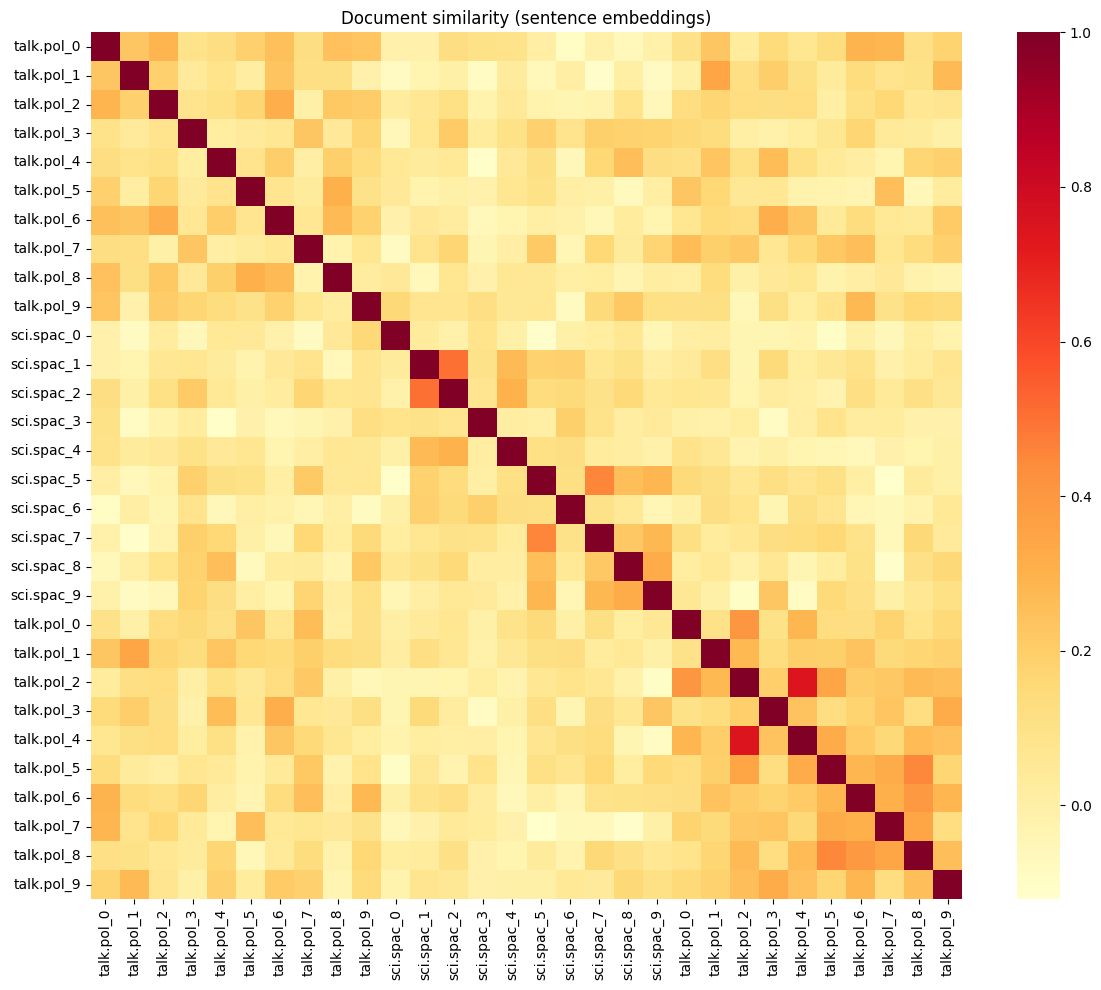

In [26]:
df_sampled = pd.concat([df_filtered[df_filtered["label_text"] == c].sample(n=10, random_state=42) for c in my_categories]).reset_index(drop=True)
sampled_docs = df_sampled["text"].str[:500].tolist()
sampled_labels = df_sampled["label_text"].tolist()

doc_embeddings = sentence_model.encode(sampled_docs)    # YOUR CODE HERE
bert_similarity = cosine_similarity(doc_embeddings)   # YOUR CODE HERE

assert doc_embeddings.shape == (30, 384) and bert_similarity.shape == (30, 30)
labels = [f"{l[:8]}_{i % 10}" for i, l in enumerate(sampled_labels)]
plt.figure(figsize=(12, 10))
sns.heatmap(bert_similarity, xticklabels=labels, yticklabels=labels, cmap="YlOrRd")
plt.title("Document similarity (sentence embeddings)")
plt.tight_layout()
plt.show()

### Question C.2 (written)

Compare with the TF-IDF heatmap of Lab 3.1 (same 30 documents):
1. Which representation groups documents of the same category better?
2. Are there documents judged similar by one method and not by the other? Why?
3. Which representation would you use for document classification? Why?

<!-- ANSWER lab3.2-C2 -->
1. Which representation groups documents of the same category better?

Sentence-BERT groups documents of the same category better overall. The heatmap shows brighter blocks within categories, especially for sci.space and talk.politics.mideast. TF-IDF showed weaker similarities and less clear grouping.

2. Are there documents judged similar by one method and not by the other? Why?

Yes, some documents have higher similarity with Sentence-BERT than with TF-IDF. This is because TF-IDF focuses on shared words, while Sentence-BERT considers the meaning and context of sentences. Two documents can discuss similar topics without using exactly the same vocabulary.

3. Which representation would you use for document classification? Why?

I would choose Sentence-BERT because it captures semantic meaning rather than just word frequencies. This is especially useful for distinguishing related categories like talk.politics.misc and talk.politics.mideast.
<!-- END ANSWER -->

### Exercise C.3 – Semantic search

In [25]:
def semantic_search(query, documents, doc_embeddings, model, top_k=5):
    """Return the top_k (index, score) pairs of the documents closest to the query."""
    # YOUR CODE HERE
    # 1. encode the query
    # 2. cosine similarity with every document embedding
    # 3. indices of the top_k highest scores
    query_embedding = model.encode([query])

    similarities = cosine_similarity(query_embedding, doc_embeddings)[0]

    top_indices = np.argsort(similarities)[::-1][:top_k]

    return [(int(i), float(similarities[i])) for i in top_indices]
    return []

my_query = "NASA space exploration and satellite missions"  # YOUR CODE HERE: a query related to ONE of your categories

results = semantic_search(my_query, sampled_docs, doc_embeddings, sentence_model, top_k=5)
assert len(results) == 5 and all(0 <= i < 30 for i, _ in results)
print(f"Query: '{my_query}'")
for idx, score in results:
    print(f"\n  score {score:.3f} | {sampled_labels[idx]}")
    print("  " + sampled_docs[idx][:150].replace("\n", " "))

Query: 'NASA space exploration and satellite missions'

  score 0.493 | sci.space
   Lets hear it for Dan Goldin...now if he can only convince the rest of our federal government that the space program is a worth while investment!  I h

  score 0.397 | sci.space
  I am doing a political science paper on the funding of NASA and pork-barrel  politics.  I would be interested in information about funding practices a

  score 0.213 | talk.politics.mideast
   I did say *any* invader, didn't I?  What do you want from me, perhaps a neural net design with all countries involved in Lebanon as its nodes? :-)  (

  score 0.203 | talk.politics.misc
  WHITE HOUSE                    OFFICE OF THE VICE PRESIDENT _________________________________________________________________  FOR IMMEDIATE RELEASE  

  score 0.184 | sci.space
  From another space forum     When workers at the Kennedy Space Center disassembled the STS-56  solid rocket boosters they were surprised to find a pai


**Question C.4 (written)**

1. Are the results relevant to the query?
2. Do they come from the expected category?
3. Try a query that could match two of your categories: what happens?




<!-- ANSWER lab3.2-C4 -->
1. Are the results relevant to the query?

For my query "NASA space exploration and satellite missions", I expect the results to be relevant because Sentence-BERT identifies documents with similar meanings, even if they use different words.

2. Do they come from the expected category?

I expect most results to come from sci.space, since the query focuses on NASA and space. Some documents from other categories could also appear if they discuss related topics.

3. Try a query that could match two of your categories: what happens?

I would try a query about governments and conflicts, which combines  talk.politics.mideast and talk.politics.misc.
<!-- END ANSWER -->

---
# Part D – Visualizing embeddings with t-SNE

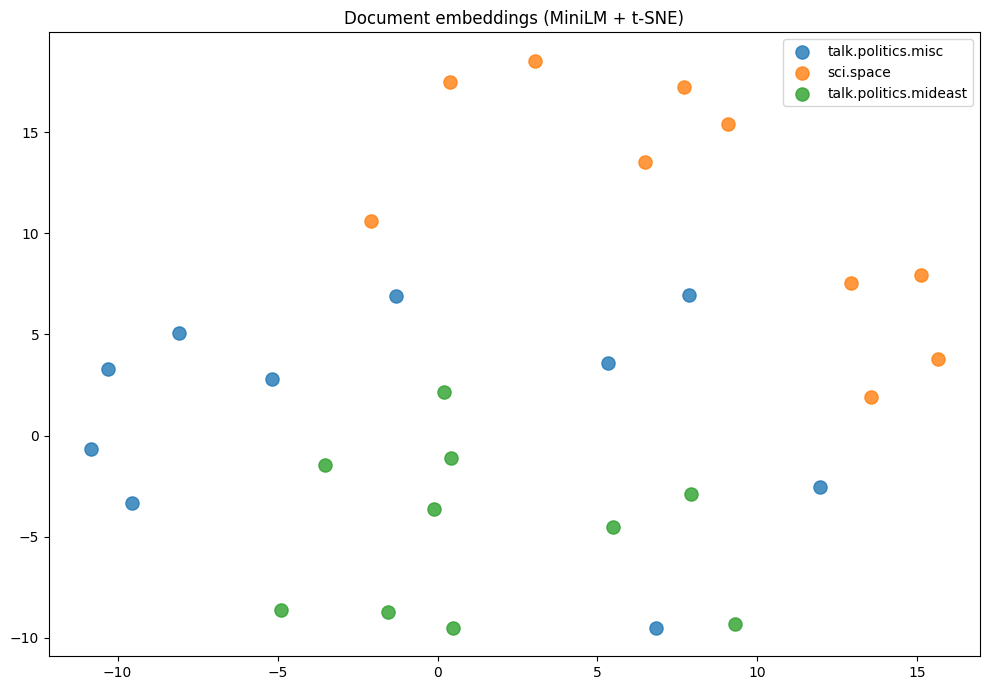

In [27]:
from sklearn.manifold import TSNE

embeddings_2d = TSNE(n_components=2, random_state=42, perplexity=10).fit_transform(doc_embeddings)
plt.figure(figsize=(10, 7))
for category in my_categories:
    mask = np.array(sampled_labels) == category
    plt.scatter(embeddings_2d[mask, 0], embeddings_2d[mask, 1], label=category, s=90, alpha=0.8)
plt.legend()
plt.title("Document embeddings (MiniLM + t-SNE)")
plt.tight_layout()
plt.show()

### Question D.1 (written)

1. Do the categories form distinct clusters?
2. Are there documents in the "wrong" cluster? What could explain it?
3. Which two categories are the closest? Does it match Lab 3.1?

<!-- ANSWER lab3.2-D1 -->
1. Do the categories form distinct clusters?

The categories form some clusters, but they are not completely separated. sci.space (orange) is mostly located in the upper part, while talk.politics.mideast (green) is mainly at the bottom. talk.politics.misc (blue) is more spread out.

2. Are there documents in the "wrong" cluster? What could explain it?

Yes, some documents appear closer to other categories than their own. This could be because they discuss overlapping topics or share similar vocabulary. Also, t-SNE reduces complex data to two dimensions, which can distort similarities.

3. Which two categories are the closest? Does it match Lab 3.1?

talk.politics.misc and talk.politics.mideast appear to be the closest overall, although there is some overlap with sci.space. This generally matches Lab 3.1, where the two political categories were expected to be more similar because they share political vocabulary.
<!-- END ANSWER -->

---
# Part E – Final comparison

### Question E.1 (written)

1. Fill in the table.

| Method | Strengths | Weaknesses | Best use case |
|--------|-----------|------------|---------------|
| BoW |simple,fast |ignores meaning |basic classification |
| TF-IDF |key-words |ignores context |topic detection |
| Word2Vec (own corpus) | domain specific| needs lots data| word similiarity|
| GloVe | general vocab|less domain specific |general NLP |
| Sentence embeddings (MiniLM) |understands meaning |computationally expensive |semantic |

2. For your categories, which method worked best overall? Support the answer with results from Labs 3.1 and 3.2.
3. For a real classification system on these categories, which representation would you choose and why?

<!-- ANSWER lab3.2-E1 -->
2. MiniLM worked best overall. In Lab 3.1, TF-IDF identified important keywords, while in Lab 3.2, MiniLM showed clearer document similarities and some category separation in the t-SNE visualization.
3. I would choose MiniLM because it understands context and meaning, which helps distinguish related political categories. However, I would compare its classification accuracy with TF-IDF before making a final decision.
<!-- END ANSWER -->

---
## Summary

- Word2Vec learns word vectors from your corpus; CBOW and Skip-gram differ in what they predict.
- Pre-trained vectors (GloVe) cover a large general vocabulary and support analogies.
- Sentence-transformer models embed whole texts and enable semantic search without shared words.
- t-SNE projects embeddings in 2-D to inspect how documents group together.

---

## Submission

1. Run the whole notebook from top to bottom (`Kernel > Restart & Run All`) and check that no cell fails.
2. Keep the outputs, save the notebook and commit it in your course repository (`nlp-course-LASTNAME`), in the same folder as in the course repository.
3. Push, then send an e-mail to the teacher to say that the work is ready. The link to the repository is only needed in your first e-mail.